In [201]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [239]:
from matplotlib.colors import LinearSegmentedColormap

# Define a diverging colormap from pink to cyan
colors = ["navy", "#f7f7f7", "tomato"]  # Pink -> White -> Cyan
cmap = LinearSegmentedColormap.from_list("tomatoNavy", colors)


In [240]:
metadata_path = "/idiap/temp/group/genomics/AstroBF_fastq/RN22346/RN22346.xlsx"
metadata = pd.read_excel(metadata_path)
metadata['category'] = metadata["Sample Genotype"] + "_" + metadata["Sample Treatment"]

In [241]:
path_analysis_per_patient = "/idiap/temp/group/genomics/AstroBF_fastq/RN22346/230106_A01366_0335_BHJJHNDSX5/genes_preprocessing/BP_analysis_per_patient/GO"


In [242]:
csv_files = glob.glob(path_analysis_per_patient + '/*.csv')


In [243]:
samples_names = []
dataframes = []
increased = []
decreased = []
for file in csv_files:
    # Extract the sample name from the file path
    sample_name = file.split('/')[-1].split('.csv')[0]
    samples_names.append(sample_name)
    df = pd.read_csv(file)
    df.replace('NA', np.NaN)
    df.dropna(inplace=True)
    increase = df[(df[f'pvalue_{sample_name}'] < 0.05) & (df[f'gene_in_GO_{sample_name}'] == 'increase')].sort_values(f'pvalue_{sample_name}')
    increased.append(increase)
    decrease = df[(df[f'pvalue_{sample_name}'] < 0.05) & (df[f'gene_in_GO_{sample_name}'] == 'decrease')].sort_values(f'pvalue_{sample_name}')
    decreased.append(decrease)
    dataframes.append(df)


In [244]:
df_pvalues = pd.DataFrame()
for df, sample_name in zip(dataframes, samples_names):
    sign_ = (df[f'gene_in_GO_{sample_name}'] == 'increase').astype(int).replace(0, -1)
    pval_log = -np.log10(df[f'pvalue_{sample_name}'])
    df_pvalues[sample_name] = sign_*pval_log
df_pvalues.index = df['Description'].values

/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero enco

In [245]:
df_pvalues

,TAH5505A15,TAH5505A17,TAH5505A3,TAH5505A18,TAH5505A2,TAH5505A7,TAH5505A8,TAH5505A9,TAH5505A6,TAH5505A4,TAH5505A16,TAH5505A5,TAH5505A14,TAH5505A1,TAH5505A12,TAH5505A10,TAH5505A13,TAH5505A11
autophagosome assembly,0.098895,0.007416,0.178704,0.148941,0.105746,0.029132,0.142080,0.324105,0.565331,0.290885,-0.043053,0.179957,0.005944,0.026686,0.077870,0.145926,0.057171,0.132588
mitotic sister chromatid segregation,-0.263892,-0.167391,-0.373109,-0.285269,0.037716,0.072856,0.042158,-0.237369,-0.718842,-0.736445,-0.175386,-0.549589,0.006196,0.029559,-0.444758,-0.575146,-0.366705,-0.488297
DNA damage checkpoint signaling,-0.130228,0.017124,-0.242072,-0.172428,-0.068656,-0.145332,-0.091118,-0.215640,-0.326914,-0.452910,-0.196045,0.002021,0.018871,-0.137775,-0.135799,-0.273380,-0.289046,-0.155763
regulation of cyclin-dependent protein serine/threonine kinase activity,5.173651,0.487336,2.618208,2.984400,1.523746,4.943540,3.312955,2.104387,0.790721,1.449807,1.569344,0.475747,1.087095,5.453638,2.714034,2.198821,2.461253,1.343622
G1/S transition of mitotic cell cycle,0.522926,0.177662,0.438696,1.327206,0.799866,0.866538,3.202870,1.342249,1.628319,0.324125,0.484616,0.333337,0.491753,0.695200,0.502302,-0.053596,0.218518,0.064840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ubiquitin-specific protease binding,1.566389,0.324514,1.682606,2.227661,2.894753,1.206849,1.795807,2.019472,1.473164,1.024367,1.078211,0.955698,1.155180,0.891258,0.703056,1.159742,1.008045,0.610646
ubiquitin ligase-substrate adaptor activity,-0.170928,-0.106687,-0.154952,-0.190970,-0.136393,-0.147953,-0.245930,-0.228531,-0.194468,-0.055498,-0.111702,-0.001196,-0.242865,-0.170591,-0.073292,-0.035931,-0.099738,-0.096639
protein tyrosine kinase binding,1.262805,0.643019,0.516088,1.168967,1.381162,2.029301,2.958486,0.891268,1.232557,0.657877,1.032230,1.489423,0.689872,2.220809,0.753572,0.483289,0.810340,0.789956
sequence-specific double-stranded DNA binding,-1.876172,-2.316266,-1.938318,-1.971006,-2.174231,-2.757423,-1.728518,-2.263644,-2.320627,-2.620598,-2.487776,-1.400607,-1.796873,-2.144441,-1.681878,-1.381027,-2.448458,-1.501529


In [246]:
df_pvalues

,TAH5505A15,TAH5505A17,TAH5505A3,TAH5505A18,TAH5505A2,TAH5505A7,TAH5505A8,TAH5505A9,TAH5505A6,TAH5505A4,TAH5505A16,TAH5505A5,TAH5505A14,TAH5505A1,TAH5505A12,TAH5505A10,TAH5505A13,TAH5505A11
autophagosome assembly,0.098895,0.007416,0.178704,0.148941,0.105746,0.029132,0.142080,0.324105,0.565331,0.290885,-0.043053,0.179957,0.005944,0.026686,0.077870,0.145926,0.057171,0.132588
mitotic sister chromatid segregation,-0.263892,-0.167391,-0.373109,-0.285269,0.037716,0.072856,0.042158,-0.237369,-0.718842,-0.736445,-0.175386,-0.549589,0.006196,0.029559,-0.444758,-0.575146,-0.366705,-0.488297
DNA damage checkpoint signaling,-0.130228,0.017124,-0.242072,-0.172428,-0.068656,-0.145332,-0.091118,-0.215640,-0.326914,-0.452910,-0.196045,0.002021,0.018871,-0.137775,-0.135799,-0.273380,-0.289046,-0.155763
regulation of cyclin-dependent protein serine/threonine kinase activity,5.173651,0.487336,2.618208,2.984400,1.523746,4.943540,3.312955,2.104387,0.790721,1.449807,1.569344,0.475747,1.087095,5.453638,2.714034,2.198821,2.461253,1.343622
G1/S transition of mitotic cell cycle,0.522926,0.177662,0.438696,1.327206,0.799866,0.866538,3.202870,1.342249,1.628319,0.324125,0.484616,0.333337,0.491753,0.695200,0.502302,-0.053596,0.218518,0.064840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ubiquitin-specific protease binding,1.566389,0.324514,1.682606,2.227661,2.894753,1.206849,1.795807,2.019472,1.473164,1.024367,1.078211,0.955698,1.155180,0.891258,0.703056,1.159742,1.008045,0.610646
ubiquitin ligase-substrate adaptor activity,-0.170928,-0.106687,-0.154952,-0.190970,-0.136393,-0.147953,-0.245930,-0.228531,-0.194468,-0.055498,-0.111702,-0.001196,-0.242865,-0.170591,-0.073292,-0.035931,-0.099738,-0.096639
protein tyrosine kinase binding,1.262805,0.643019,0.516088,1.168967,1.381162,2.029301,2.958486,0.891268,1.232557,0.657877,1.032230,1.489423,0.689872,2.220809,0.753572,0.483289,0.810340,0.789956
sequence-specific double-stranded DNA binding,-1.876172,-2.316266,-1.938318,-1.971006,-2.174231,-2.757423,-1.728518,-2.263644,-2.320627,-2.620598,-2.487776,-1.400607,-1.796873,-2.144441,-1.681878,-1.381027,-2.448458,-1.501529


In [247]:
treatments = {'ctrl2_basal': ['TAH5505A1'], 
              'glib_basal': ['TAH5505A10'], 
              'glib_A1 low': ['TAH5505A11'], 
              'glib_A1 high': ['TAH5505A12'], 
              'cbie_basal': ['TAH5505A13'], 
              'cbie_A1 low': ['TAH5505A14'], 
              'cbie_A1 high': ['TAH5505A15'], 
              'ctrl6_basal': ['TAH5505A16'], 
              'ctrl6_A1 low': ['TAH5505A17'], 
              'ctrl6_A1 high': ['TAH5505A18'], 
              'ctrl2_A1 low': ['TAH5505A2'], 
              'ctrl2_A1 high': ['TAH5505A3'], 
              'ctrl3_basal': ['TAH5505A4'], 
              'ctrl3_A1 low': ['TAH5505A5'], 
              'ctrl3_A1 high': ['TAH5505A6'], 
              'glia_basal': ['TAH5505A7'], 
              'glia_A1 low': ['TAH5505A8'], 
              'glia_A1 high': ['TAH5505A9']}

treatments_cell_lines = {'ctrl_basal': ['TAH5505A1', 'TAH5505A16', 'TAH5505A4'],
 'ctrl_A1 low': ['TAH5505A17', 'TAH5505A2', 'TAH5505A5'],
 'ctrl_A1 high': ['TAH5505A18', 'TAH5505A3', 'TAH5505A6'],
 'vcp_basal': ['TAH5505A10', 'TAH5505A13', 'TAH5505A7'],
 'vcp_A1 low': ['TAH5505A11', 'TAH5505A14', 'TAH5505A8'],
 'vcp_A1 high': ['TAH5505A12', 'TAH5505A15', 'TAH5505A9']}

palette_genotype = {"ctrl_basal": 'palegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "forestgreen", "vcp_basal": "pink", "vcp_A1 low": "hotpink", "vcp_A1 high": "deeppink" }
palette_treatments = {"ctrl_basal": 'dimgray', "ctrl_A1 low": "deepskyblue", "ctrl_A1 high": "darkorange", "vcp_basal": "dimgray", "vcp_A1 low": "deepskyblue", "vcp_A1 high": "darkorange" }

In [248]:
for condition, samples in treatments_cell_lines.items():
    df_pvalues[condition] = df_pvalues[samples].mean(axis=1)
    df_pvalues.drop(samples, axis=1, inplace=True)

In [249]:
df_pvalues

,ctrl_basal,ctrl_A1 low,ctrl_A1 high,vcp_basal,vcp_A1 low,vcp_A1 high
autophagosome assembly,0.091506,0.097706,0.297659,0.077410,0.093537,0.166957
mitotic sister chromatid segregation,-0.294091,-0.226421,-0.459073,-0.289665,-0.146648,-0.315340
DNA damage checkpoint signaling,-0.262244,-0.016504,-0.247138,-0.235919,-0.076003,-0.160555
regulation of cyclin-dependent protein serine/threonine kinase activity,2.824263,0.828943,2.131110,3.201204,1.914557,3.330691
G1/S transition of mitotic cell cycle,0.501313,0.436955,1.131407,0.343820,1.253155,0.789159
...,...,...,...,...,...,...
ubiquitin-specific protease binding,0.997946,1.391655,1.794477,1.124878,1.187211,1.429639
ubiquitin ligase-substrate adaptor activity,-0.112597,-0.081425,-0.180130,-0.094541,-0.195145,-0.157584
protein tyrosine kinase binding,1.303638,1.171202,0.972538,1.107643,1.479438,0.969215
sequence-specific double-stranded DNA binding,-2.417605,-1.963701,-2.076650,-2.195636,-1.675640,-1.940565


In [250]:
# More robust cleaning of infinite and NaN values
print("Data shape before cleaning:", df_pvalues.shape)
print("Number of infinite values:", np.isinf(df_pvalues).sum().sum())
print("Number of NaN values:", df_pvalues.isna().sum().sum())

# Replace infinite values with the maximum finite value
max_finite_value = df_pvalues.replace([np.inf, -np.inf], np.nan).max().max()
df_pvalues = df_pvalues.replace([np.inf, -np.inf], max_finite_value)

# Fill any remaining NaN values with 0
df_pvalues = df_pvalues.fillna(0)

print("After cleaning:")
print("Number of infinite values:", np.isinf(df_pvalues).sum().sum())
print("Number of NaN values:", df_pvalues.isna().sum().sum())
print("Data range:", df_pvalues.min().min(), "to", df_pvalues.max().max())

Data shape before cleaning: (2112, 6)
Number of infinite values: 789
Number of NaN values: 0
After cleaning:
Number of infinite values: 0
Number of NaN values: 0
Data range: -4.520266077493456 to 13.875100556490077


In [251]:
df_filtered = df_pvalues[(df_pvalues.abs() > -np.log(0.05)).any(axis=1)]   


In [252]:
import seaborn as sns
import matplotlib.pyplot as plt



# Additional data cleaning for clustering
print("Before additional cleaning:")
print("Data shape:", df_filtered.shape)
print("Data range:", df_filtered.min().min(), "to", df_filtered.max().max())

# Remove rows with zero variance (all identical values)
row_variance = df_filtered.var(axis=1)
print(f"Rows with zero variance: {(row_variance == 0).sum()}")
df_clean = df_filtered[row_variance > 0]

# Remove columns with zero variance  
col_variance = df_clean.var(axis=0)
print(f"Columns with zero variance: {(col_variance == 0).sum()}")
df_clean = df_clean.loc[:, col_variance > 0]

col_colors_clean = [palette_treatments[condition] for condition in df_clean.columns]

print("After cleaning:")
print("Data shape:", df_clean.shape)
print("Data range:", df_clean.min().min(), "to", df_clean.max().max())

# Verify that we have finite values for clustering
print("Final check - any infinite or NaN values:", 
      np.isinf(df_clean).any().any() or df_clean.isna().any().any())

# Create clustermap with multiple fallback options


Before additional cleaning:
Data shape: (592, 6)
Data range: -4.520266077493456 to 13.875100556490077
Rows with zero variance: 55
Columns with zero variance: 0
After cleaning:
Data shape: (537, 6)
Data range: -4.520266077493456 to 13.875100556490077
Final check - any infinite or NaN values: False


[Text(0.5, 0, 'ctrl_basal'),
 Text(1.5, 0, 'vcp_basal'),
 Text(2.5, 0, 'ctrl_A1 low'),
 Text(3.5, 0, 'vcp_A1 low'),
 Text(4.5, 0, 'ctrl_A1 high'),
 Text(5.5, 0, 'vcp_A1 high')]

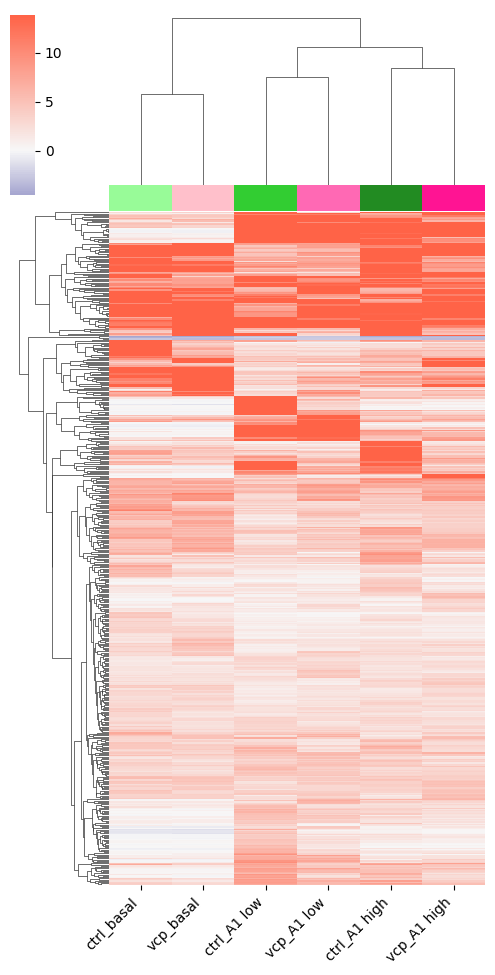

In [253]:
col_colors_clean = [palette_genotype[condition] for condition in df_clean.columns]

# Create clustermap with multiple fallback options

# First try with standard scaling
g = sns.clustermap(df_clean, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=False, 
                    cmap=cmap, 
                    center=0,
                    figsize=(5, 10))

g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(), 
    rotation=45, 
    ha='right'
)


[Text(0.5, 0, 'ctrl_basal'),
 Text(1.5, 0, 'vcp_basal'),
 Text(2.5, 0, 'ctrl_A1 low'),
 Text(3.5, 0, 'vcp_A1 low'),
 Text(4.5, 0, 'ctrl_A1 high'),
 Text(5.5, 0, 'vcp_A1 high')]

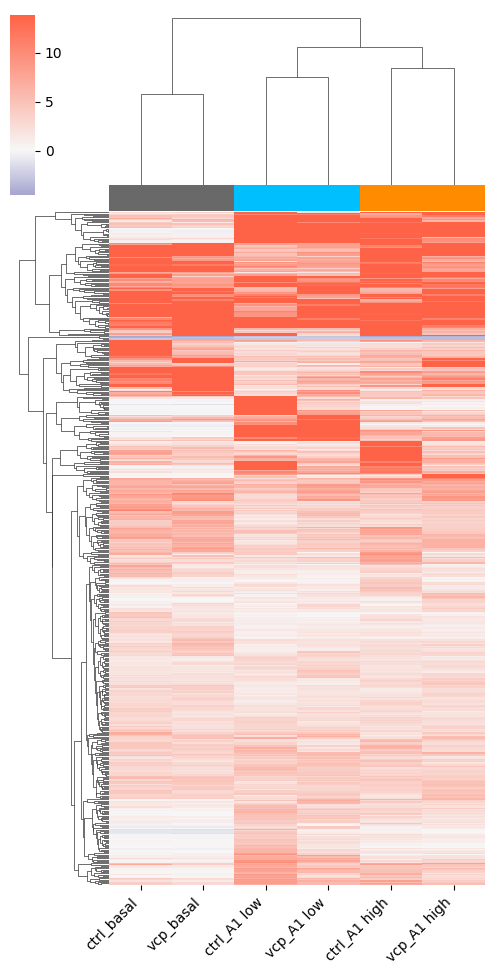

In [254]:
col_colors_clean = [palette_treatments[condition] for condition in df_clean.columns]

# Create clustermap with multiple fallback options

# First try with standard scaling
g = sns.clustermap(df_clean, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=False, 
                    cmap=cmap, 
                    center=0,
                    figsize=(5, 10))

g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(), 
    rotation=45, 
    ha='right'
)

In [255]:
treatments = {k: [k] for k in df_pvalues.columns}

In [256]:
from melapa.OmicsDataset import OmicsDataset

pvalues_dataset = OmicsDataset(df=df_pvalues, 
                               treatments=treatments, 
                               nb_comp=6, 
                               df_log=df_pvalues)

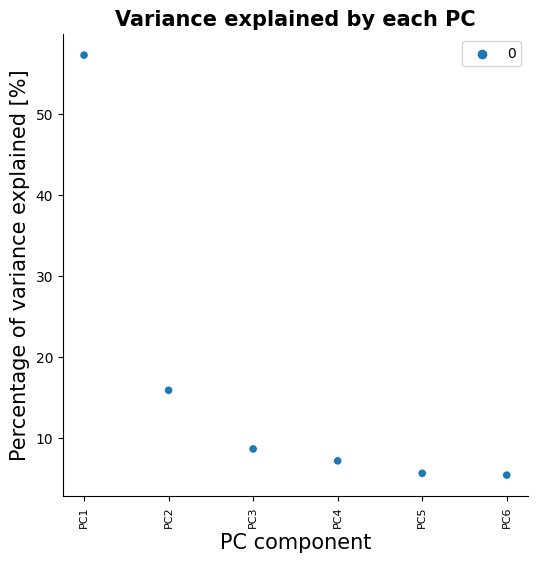

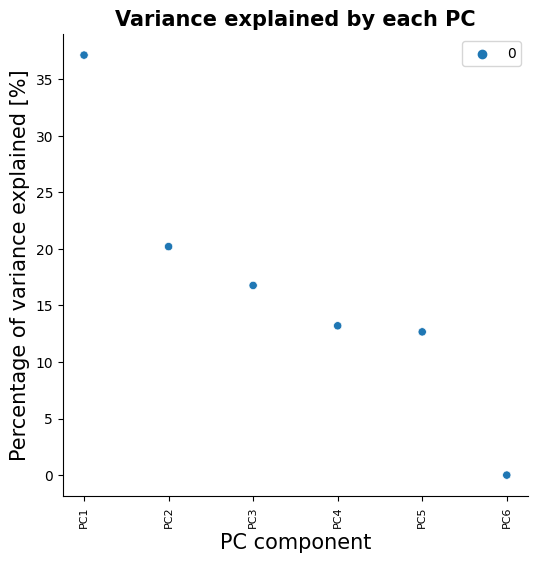

In [257]:
pvalues_dataset.perform_svd_analysis(top_n=6)

In [258]:
pvalues_dataset.pca['Sample Treatment'] = pvalues_dataset.pca['treatment'].apply(lambda x: x.split('_')[1])
pvalues_dataset.pca['Sample Genotype'] = pvalues_dataset.pca['treatment'].apply(lambda x: x.split('_')[0])
pvalues_dataset.pca['mutation'] = pvalues_dataset.pca['treatment'].apply(lambda x: x.split('_')[0])



In [259]:
pvalues_dataset.pca

,PC1,PC2,PC3,PC4,PC5,PC6,treatment,Sample Treatment,Sample Genotype,mutation
ctrl_basal,-61.647433,-6.913370,25.927485,-13.964425,-20.488209,1.647121e-13,ctrl_basal,basal,ctrl,ctrl
ctrl_A1 low,71.692018,-8.350604,27.787733,-10.971570,16.092549,1.672175e-13,ctrl_A1 low,A1 low,ctrl,ctrl
ctrl_A1 high,10.138996,55.516851,-0.346101,12.263126,-4.476073,1.829321e-13,ctrl_A1 high,A1 high,ctrl,ctrl
vcp_basal,-62.732012,-14.066968,-0.921707,17.652834,24.960220,1.639770e-13,vcp_basal,basal,vcp,vcp
vcp_A1 low,41.320524,-30.831010,-12.985963,20.515048,-19.271203,1.697426e-13,vcp_A1 low,A1 low,vcp,vcp
vcp_A1 high,-2.380137,-0.461856,-37.174151,-25.659231,3.894265,1.748108e-13,vcp_A1 high,A1 high,vcp,vcp


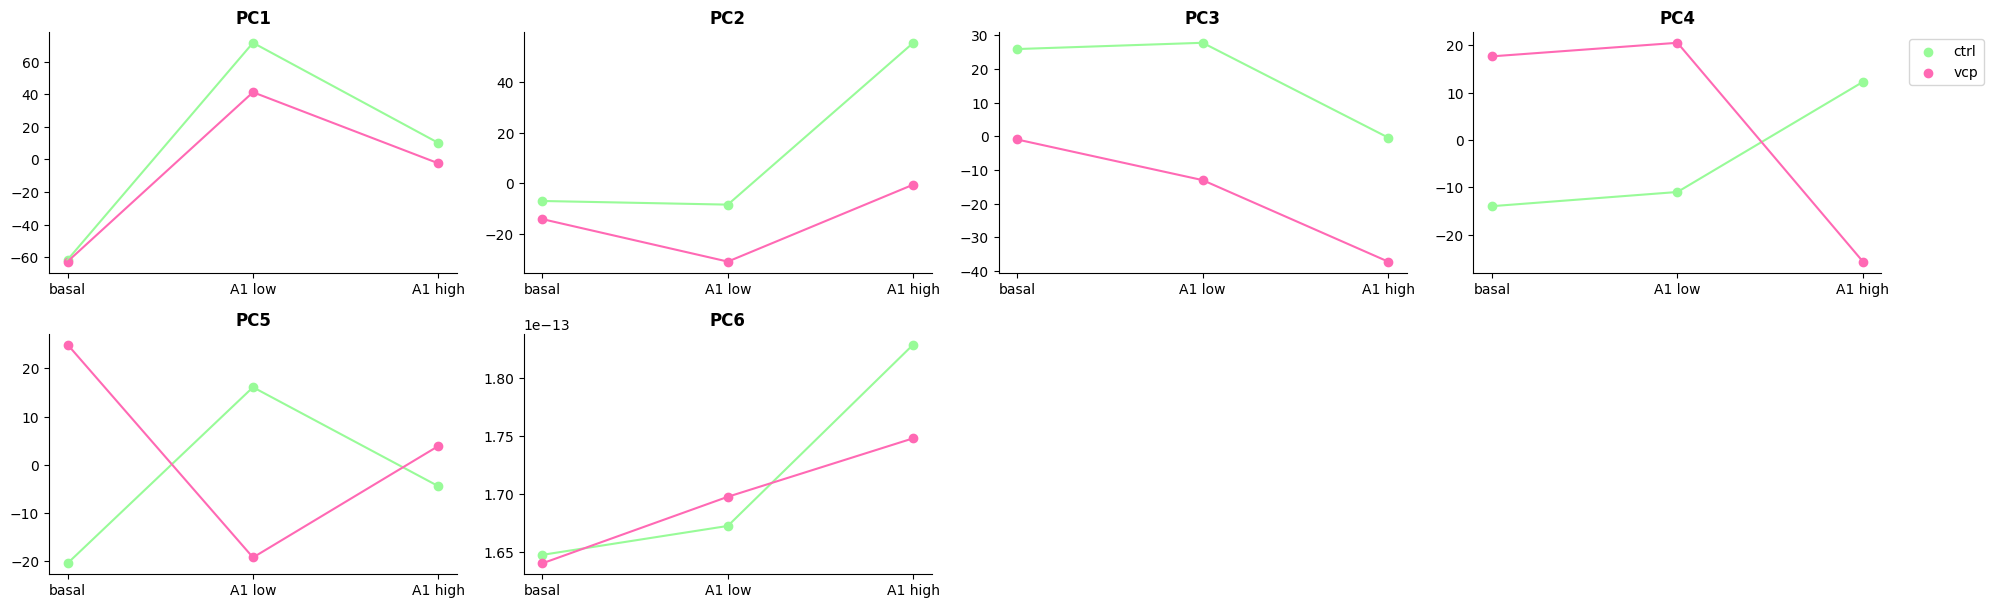

In [260]:
palette_genotype = {"ctrl": 'palegreen', "vcp": "hotpink"}
plt.figure(figsize=(20, 15))
for pc in range(6):
    plt.subplot(5, 4, pc+1)
    for genotype in pvalues_dataset.pca['Sample Genotype'].unique():
        subset = pvalues_dataset.pca[pvalues_dataset.pca['Sample Genotype'] == genotype]
        # subset.index = [idx.split('_')[1] for idx in subset.index]
        subset.set_index("Sample Treatment", inplace=True)
        subset = subset.loc[["basal", "A1 low", "A1 high"]]
        plt.scatter(x=subset.index, y=subset[f'PC{pc+1}'], label=genotype, color=palette_genotype[genotype])
        plt.plot(subset.index, subset[f'PC{pc+1}'], color=palette_genotype[genotype])
    if pc == 3:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    sns.despine()
    plt.title(f"PC{pc+1}", weight='bold')
plt.tight_layout()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=7.80e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=3.09e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=6.93e-02
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=6.56e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=7.30e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=7.66e-01


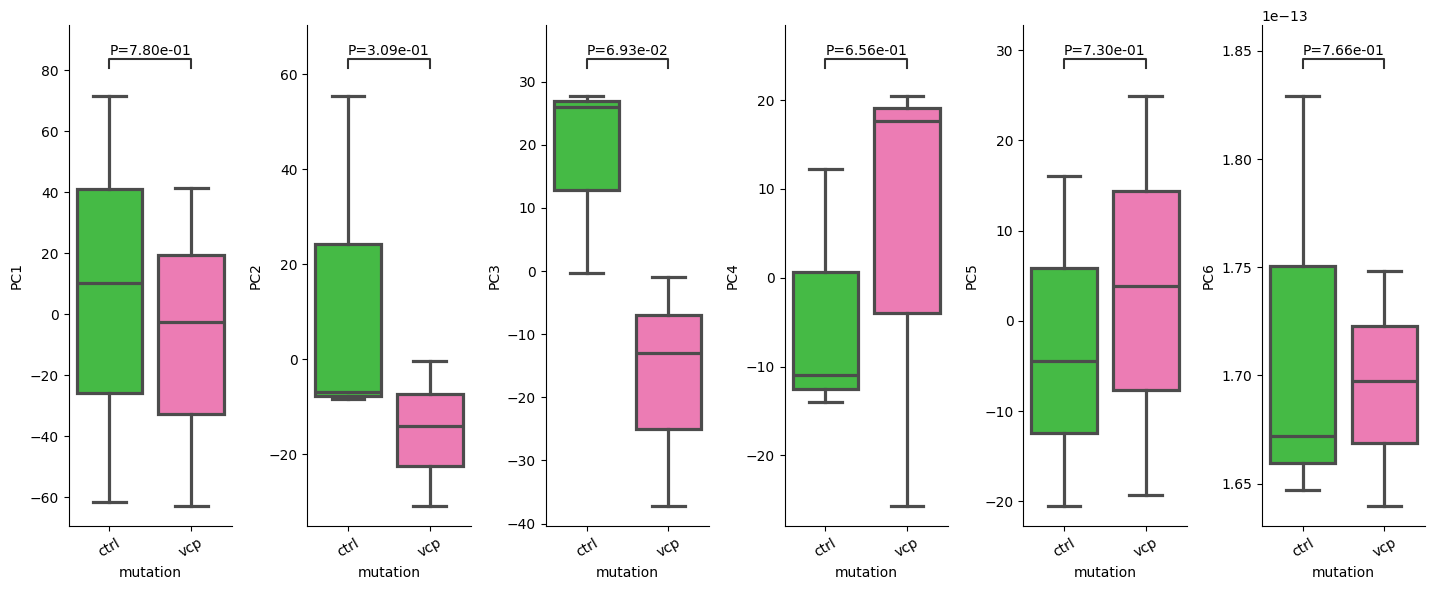

In [261]:
from melapa.helper_plot import boxplot_pca_significance

boxplot_pca_significance(pvalues_dataset.pca, treatment_col='mutation', fontsize=10, palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})

In [262]:
pvalues_dataset.pca['treatment'] = pvalues_dataset.pca['Sample Treatment']

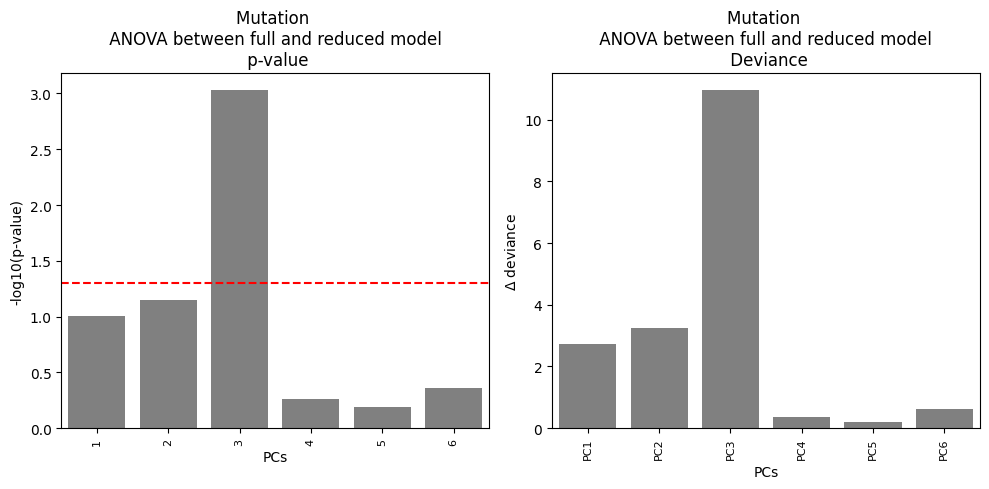

In [263]:
%%capture cap --no-display

from melapa.LMM_helper import lmer_per_PC_re

## See which component captures the difference sensitive/resistant

plt.figure(figsize=(10, 5))
## See which component captures the batch
anovas = []
p_vals = []

for i in range(6):
    PC = i+1
    anova, p_val = lmer_per_PC_re(pvalues_dataset.pca, random_effects=['treatment'], fixed_effect='mutation', PC=PC)
    anovas.append(anova)
    p_vals.append(p_val)

plt.subplot(1, 2, 1)
sns.barplot(x=np.arange(1, 7), y=-np.log10(p_vals), color='grey')
plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel('-log10(p-value)')
plt.title(f'Mutation \n ANOVA between full and reduced model \n p-value')

delta_deviances = []
for PC in range(len(anovas)):
    delta_deviance = anovas[PC].loc['MODEL2', 'deviance'] - anovas[PC].loc['MODEL1', 'deviance'] ## Difference between the full and reduced model
    delta_deviances.append(delta_deviance)

plt.subplot(1, 2, 2)
sns.barplot(x=[f"PC{i+1}" for i in range(len(anovas))], y=delta_deviances, color='grey')
#plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel(r'$\Delta$ deviance')
plt.title(f'Mutation \n ANOVA between full and reduced model \n Deviance')

plt.tight_layout()

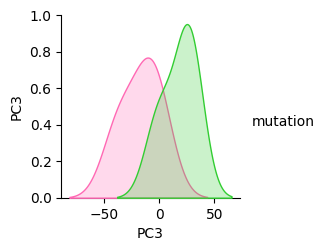

In [264]:
PCs = [f"PC{PC+1}" for PC in list(np.argwhere(np.array(p_vals) < 0.05).flatten())] + ['mutation']
sns.pairplot(pvalues_dataset.pca[PCs], hue='mutation',  palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=8.07e-02
A1 low vs. A1 high: P=1.41e-01
basal vs. A1 high: P=5.84e-02
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=5.63e-01
A1 low vs. A1 high: P=3.17e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


basal vs. A1 high: P=4.01e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=8.56e-01
A1 low vs. A1 high: P=4.42e-01
basal vs. A1 high: P=3.14e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=9.08e-01
A1 low vs. A1 high: P=6.89e-01
basal vs. A1 high: P=7.63e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=9.07e-01
A1 low vs. A1 high: P=9.54e-01
basal vs. A1 high: P=9.30e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

basal vs. A1 low: P=1.66e-01
A1 low vs. A1 high: P=2.14e-01
basal vs. A1 high: P=1.71e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


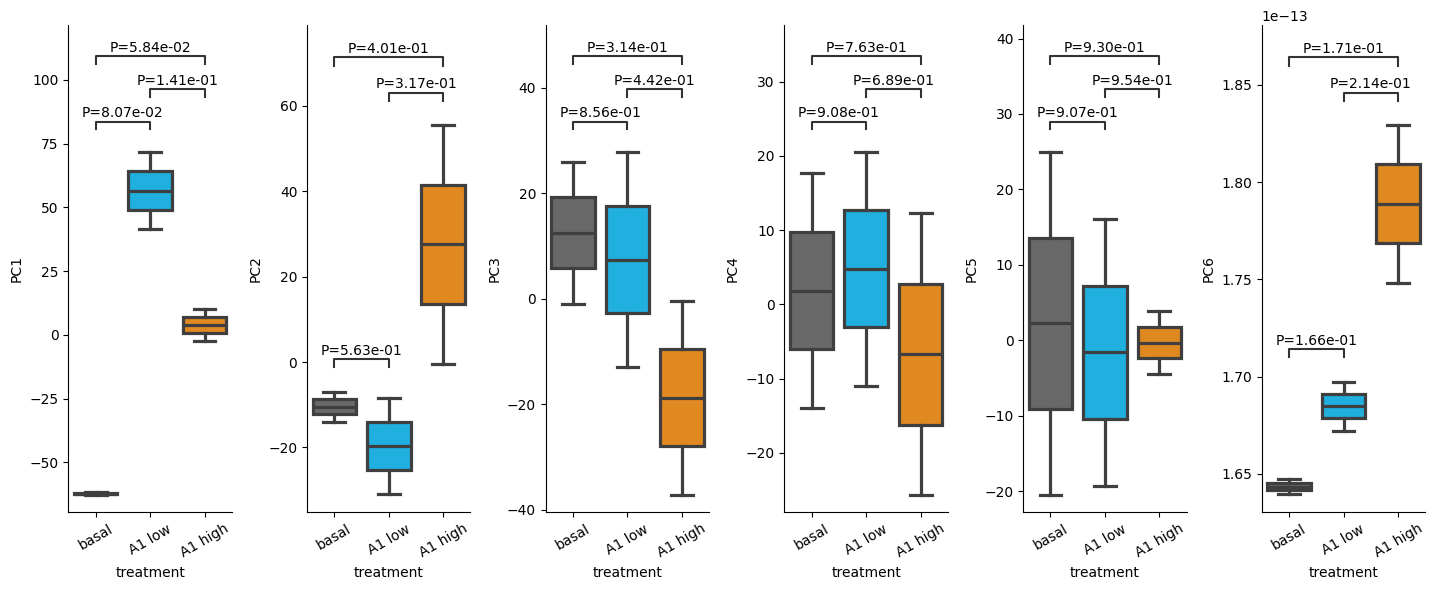

In [265]:
boxplot_pca_significance(pvalues_dataset.pca, treatment_col='treatment', fontsize=10, palette={'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"})

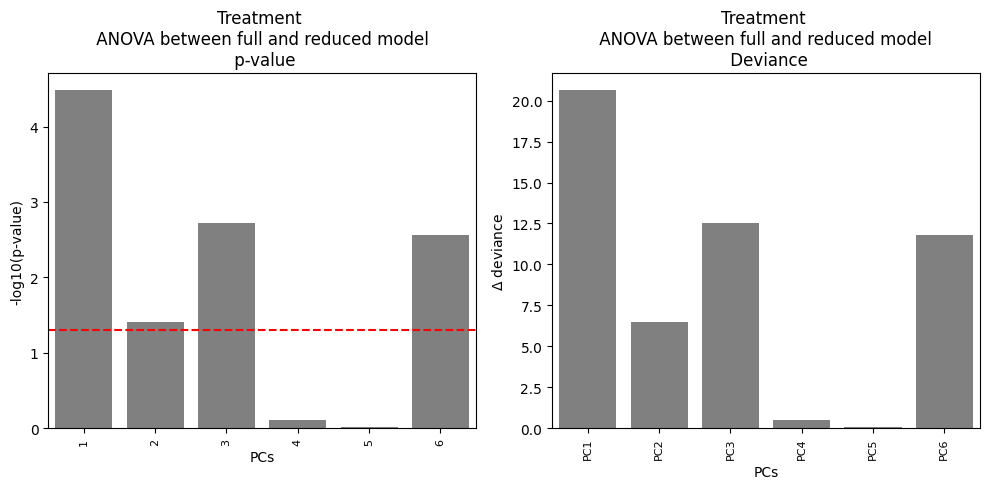

In [266]:
%%capture cap --no-display

from melapa.LMM_helper import lmer_per_PC_re

## See which component captures the difference sensitive/resistant

plt.figure(figsize=(10, 5))
## See which component captures the batch
anovas = []
p_vals = []

for i in range(6):
    PC = i+1
    anova, p_val = lmer_per_PC_re(pvalues_dataset.pca, random_effects=['mutation'], fixed_effect='treatment', PC=PC)
    anovas.append(anova)
    p_vals.append(p_val)

plt.subplot(1, 2, 1)
sns.barplot(x=np.arange(1, 7), y=-np.log10(p_vals), color='grey')
plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel('-log10(p-value)')
plt.title(f'Treatment \n ANOVA between full and reduced model \n p-value')

delta_deviances = []
for PC in range(len(anovas)):
    delta_deviance = anovas[PC].loc['MODEL2', 'deviance'] - anovas[PC].loc['MODEL1', 'deviance'] ## Difference between the full and reduced model
    delta_deviances.append(delta_deviance)

plt.subplot(1, 2, 2)
sns.barplot(x=[f"PC{i+1}" for i in range(len(anovas))], y=delta_deviances, color='grey')
#plt.axhline(y=-np.log10(0.05), color='red', linestyle='--')
plt.xticks(rotation=90, fontsize=8);
plt.xlabel('PCs')
plt.ylabel(r'$\Delta$ deviance')
plt.title(f'Treatment \n ANOVA between full and reduced model \n Deviance')

plt.tight_layout()

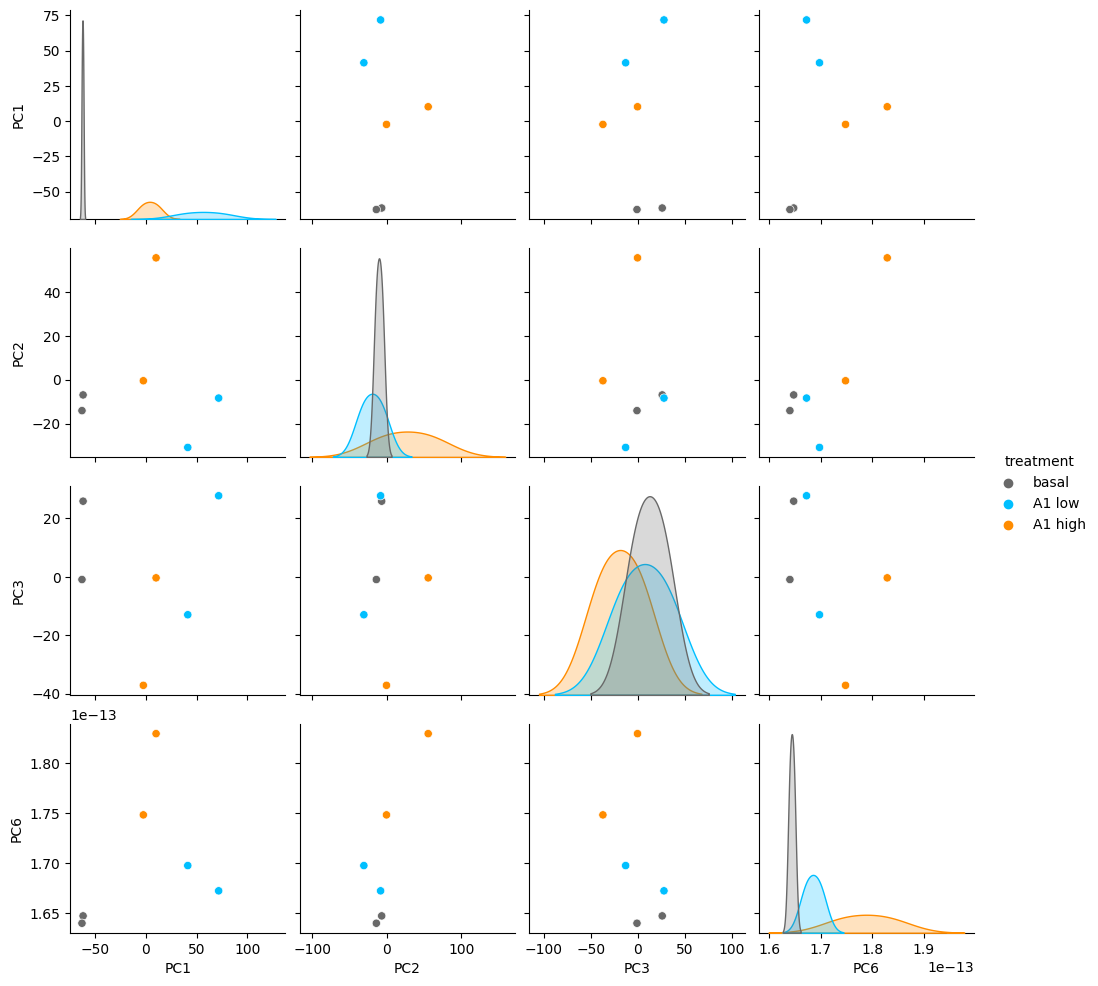

In [267]:
PCs = [f"PC{PC+1}" for PC in list(np.argwhere(np.array(p_vals) < 0.05).flatten())] + ['treatment']
sns.pairplot(pvalues_dataset.pca[PCs], hue='treatment',  palette={'basal': 'dimgray', 'A1 low': 'deepskyblue', "A1 high": "darkorange"})

In [268]:
projection_PC1 = pvalues_dataset.Vt_w1[0]
indexes_top = np.argsort(projection_PC1)[-50:]
indexes_bottom = np.argsort(projection_PC1)[:50]

top_highest_PC1 = list(pvalues_dataset.df.reset_index().iloc[indexes_top]['index'].values)
top_lowest_PC1 = list(pvalues_dataset.df.reset_index().iloc[indexes_bottom]['index'].values)



In [269]:
top_proj40 = pd.concat([
              pvalues_dataset.X_without_PC1.T.loc[top_highest_PC1],
              pvalues_dataset.X_without_PC1.T.loc[top_lowest_PC1],
              ]).drop_duplicates(keep='first')


# top_proj40 = top_proj40[ordered_treatments]

After cleaning:
Data shape: (100, 6)
Data range: -9.278733853732474 to 11.324891249561551
Final check - any infinite or NaN values: False


[Text(0.5, 0, 'ctrl_basal'),
 Text(1.5, 0, 'vcp_basal'),
 Text(2.5, 0, 'ctrl_A1 high'),
 Text(3.5, 0, 'vcp_A1 high'),
 Text(4.5, 0, 'ctrl_A1 low'),
 Text(5.5, 0, 'vcp_A1 low')]

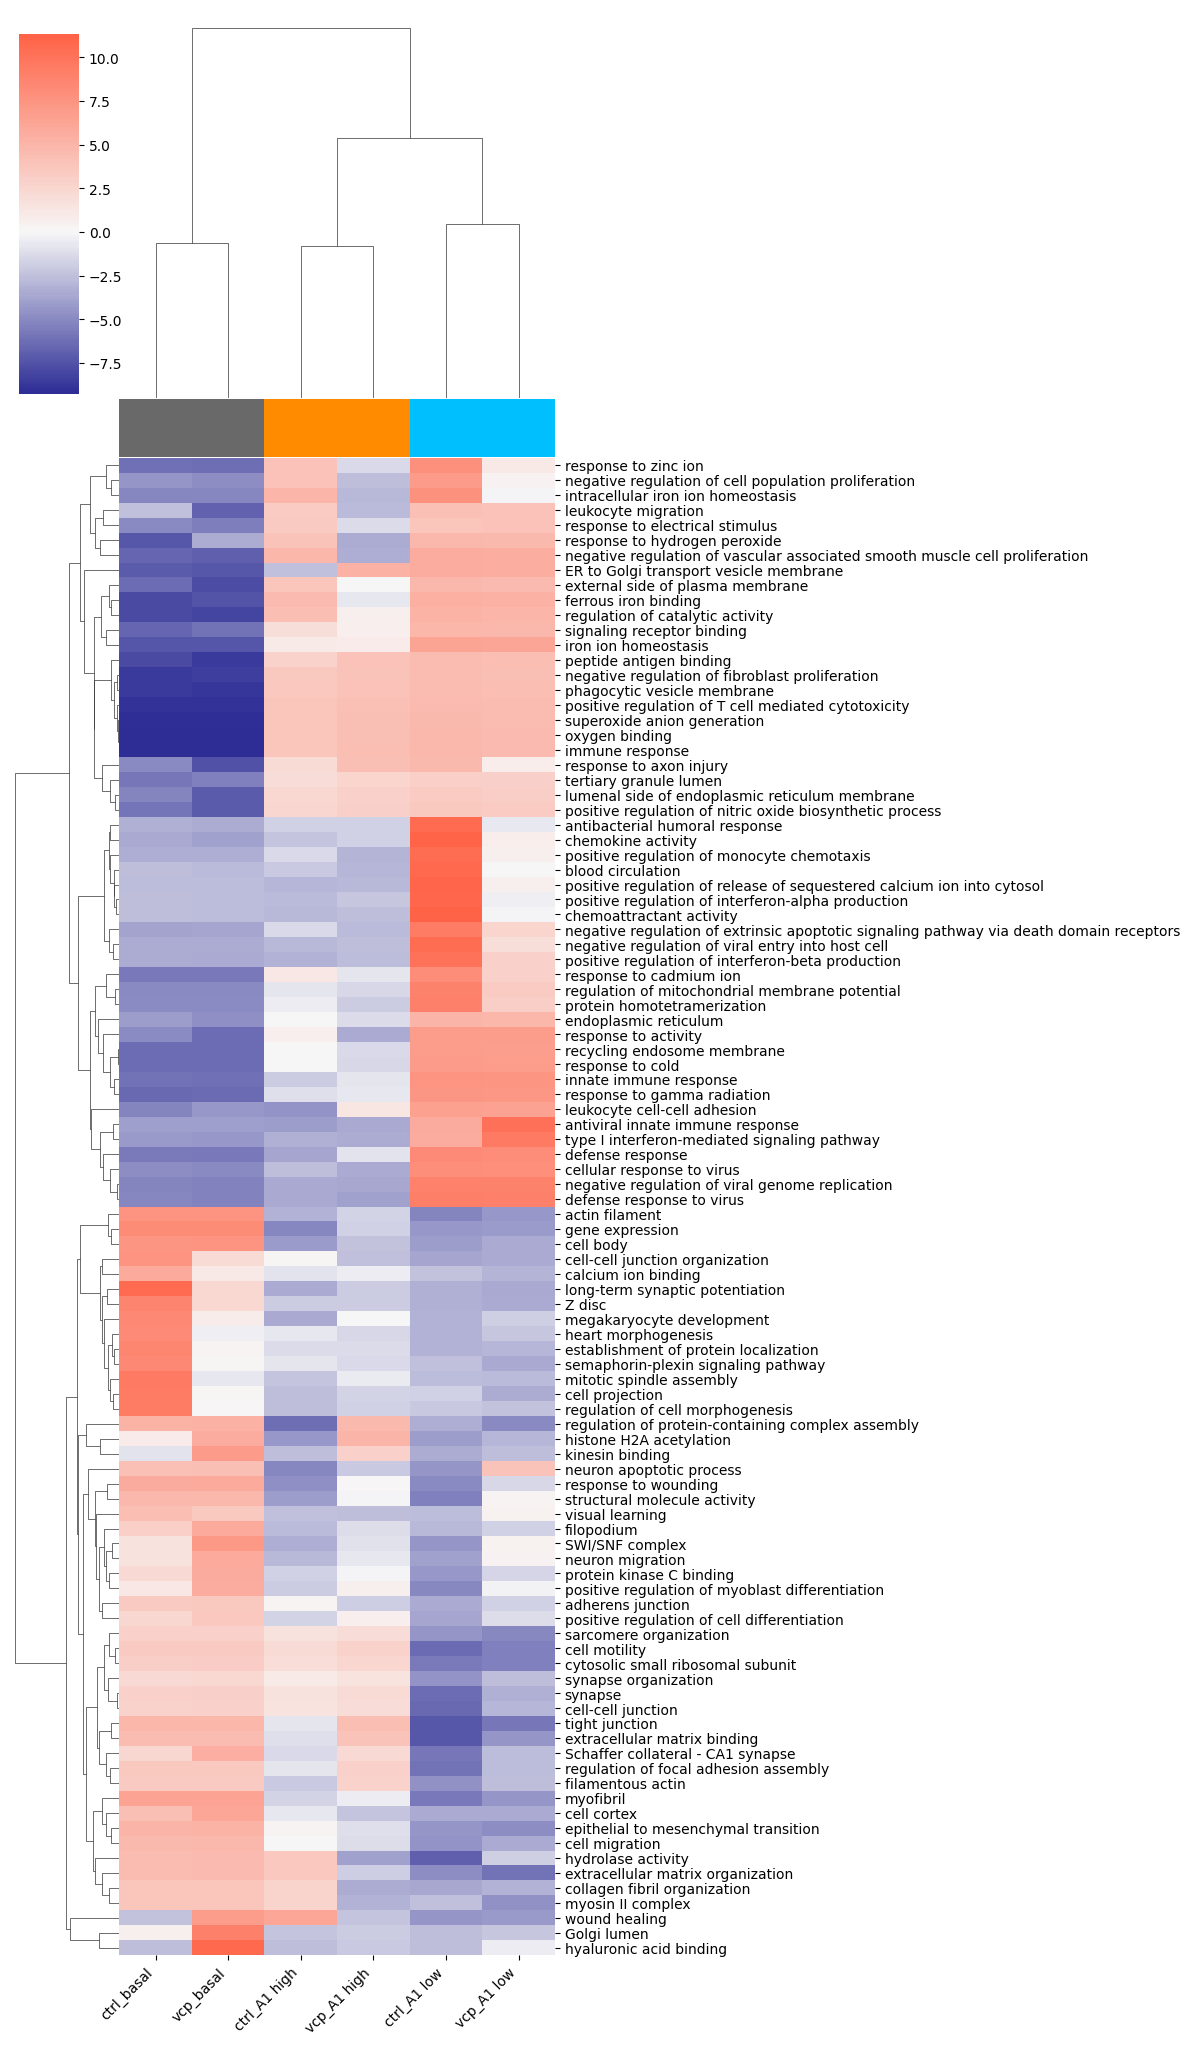

In [270]:
# Update col_colors to match remaining columns
col_colors_clean = [palette_treatments[treatment] for treatment in top_proj40.columns]

print("After cleaning:")
print("Data shape:", top_proj40.shape)
print("Data range:", top_proj40.min().min(), "to", top_proj40.max().max())

# Verify that we have finite values for clustering
print("Final check - any infinite or NaN values:", 
      np.isinf(top_proj40).any().any() or top_proj40.isna().any().any())

# Create clustermap with multiple fallback options

# First try with standard scaling
g = sns.clustermap(top_proj40, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=True, 
                    cmap=cmap, 
                    center=0,
                    figsize=(12, 20))
g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(), 
    rotation=45, 
    ha='right'
)

In [271]:
projection_PC3 = pvalues_dataset.Vt_w1[2]
indexes_top = np.argsort(projection_PC3)[-50:]
indexes_bottom = np.argsort(projection_PC3)[:50]

top_highest_PC3 = list(pvalues_dataset.df.reset_index().iloc[indexes_top]['index'].values)
top_lowest_PC3 = list(pvalues_dataset.df.reset_index().iloc[indexes_bottom]['index'].values)

In [272]:
top_proj40 = pd.concat([
              pvalues_dataset.X_without_PC1.T.loc[top_highest_PC3],
              pvalues_dataset.X_without_PC1.T.loc[top_lowest_PC3],
              ]).drop_duplicates(keep='first')




In [273]:
palette_genotype = {"ctrl_basal": 'palegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "forestgreen", "vcp_basal": "pink", "vcp_A1 low": "hotpink", "vcp_A1 high": "deeppink" }

# palette_genotype = {"ctrl_basal": 'limegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "limegreen", "vcp_basal": "hotpink", "vcp_A1 low": "hotpink", "vcp_A1 high": "hotpink" }



[Text(0.5, 0, 'ctrl_basal'),
 Text(1.5, 0, 'vcp_basal'),
 Text(2.5, 0, 'ctrl_A1 low'),
 Text(3.5, 0, 'ctrl_A1 high'),
 Text(4.5, 0, 'vcp_A1 low'),
 Text(5.5, 0, 'vcp_A1 high')]

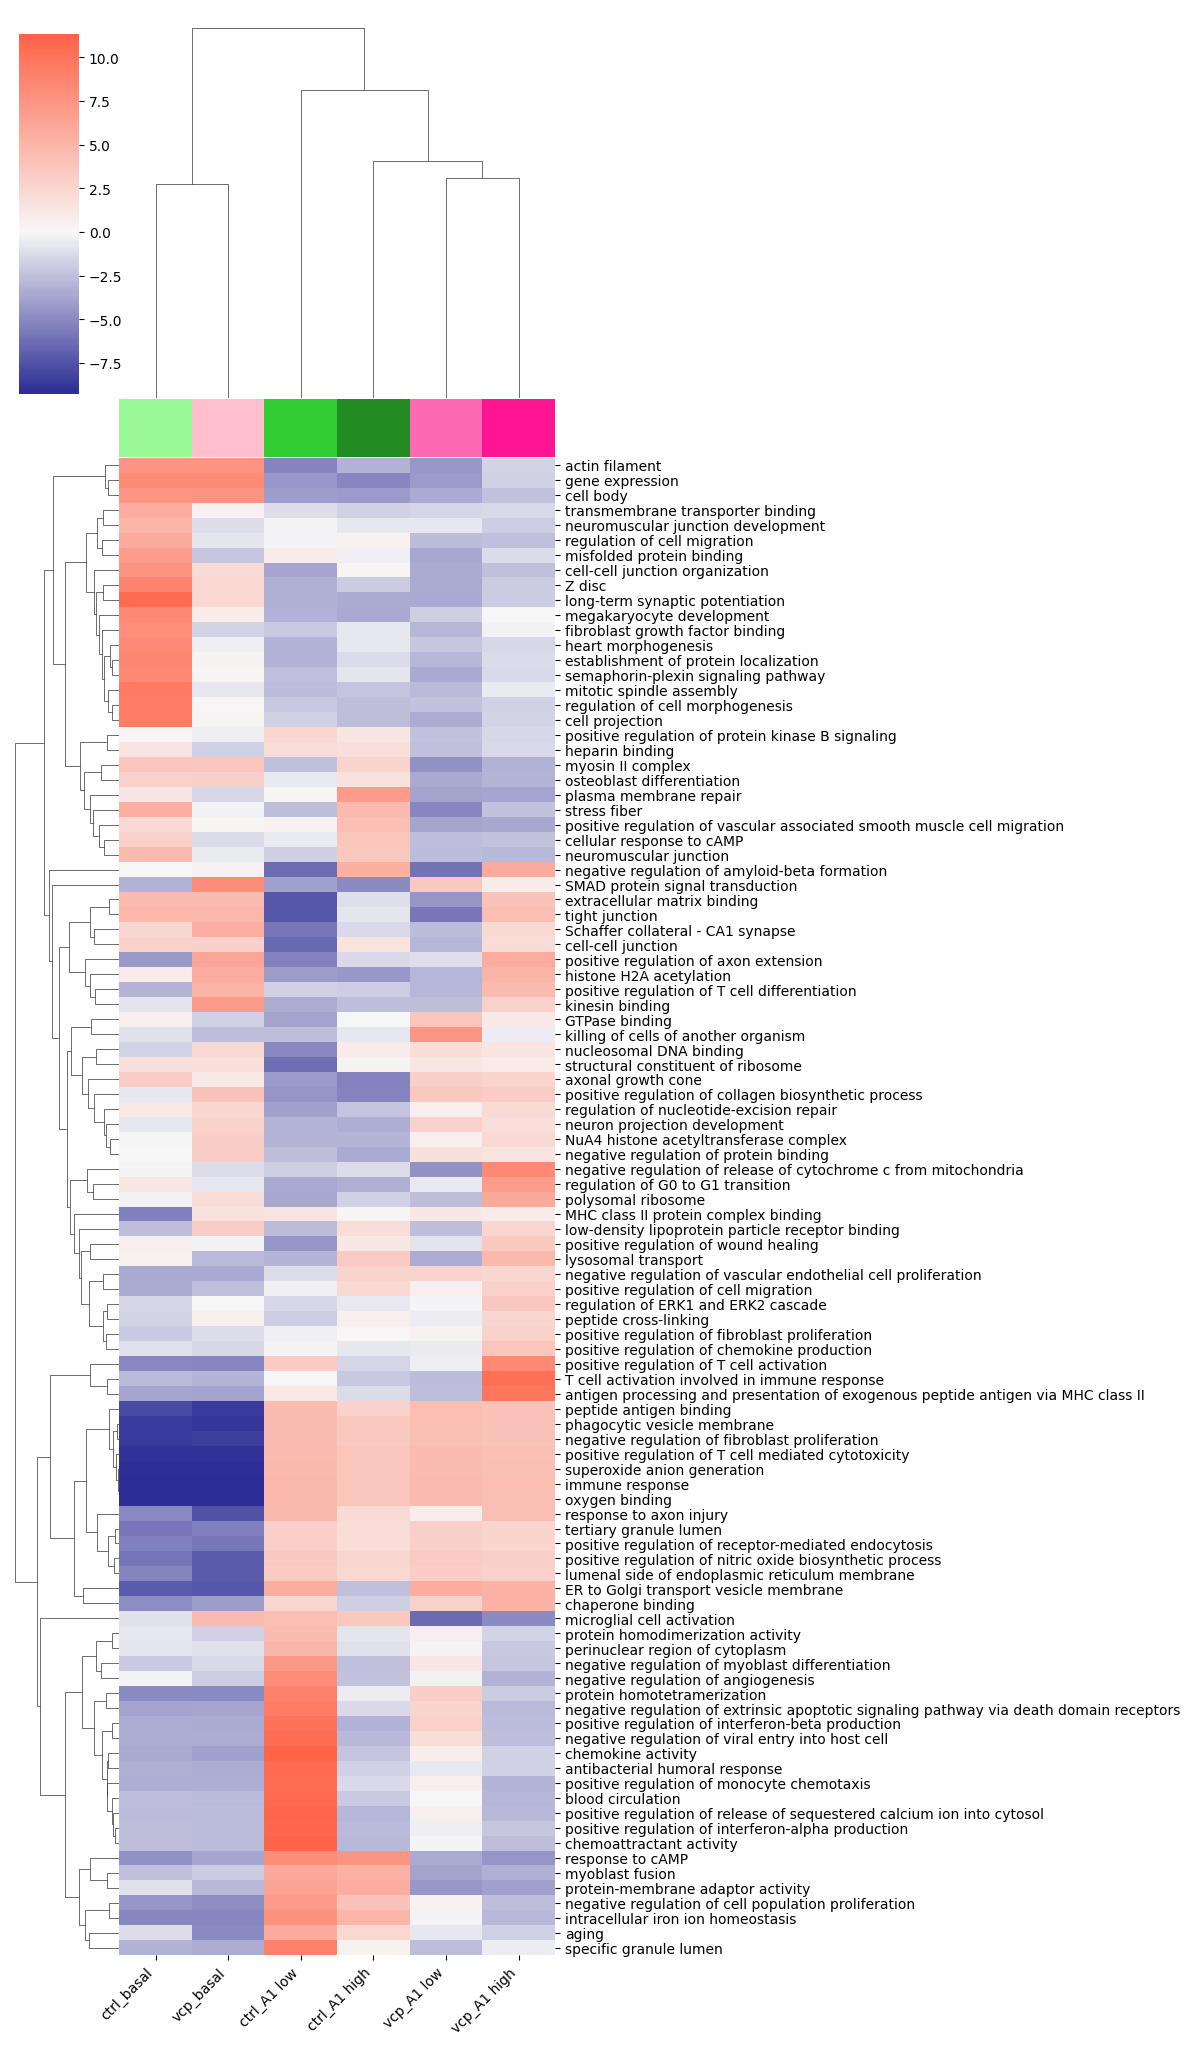

In [274]:

# Update col_colors to match remaining columns
col_colors_clean = [palette_genotype[treatment] for treatment in top_proj40.columns]
            
            
# First try with standard scaling
g = sns.clustermap(top_proj40, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=True, 
    cmap=cmap,
    center=0,  
                    figsize=(12, 20))


g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(), 
    rotation=45, 
    ha='right'
)

[Text(0.5, 0, 'ctrl_basal'),
 Text(1.5, 0, 'vcp_basal'),
 Text(2.5, 0, 'ctrl_A1 low'),
 Text(3.5, 0, 'ctrl_A1 high'),
 Text(4.5, 0, 'vcp_A1 low'),
 Text(5.5, 0, 'vcp_A1 high')]

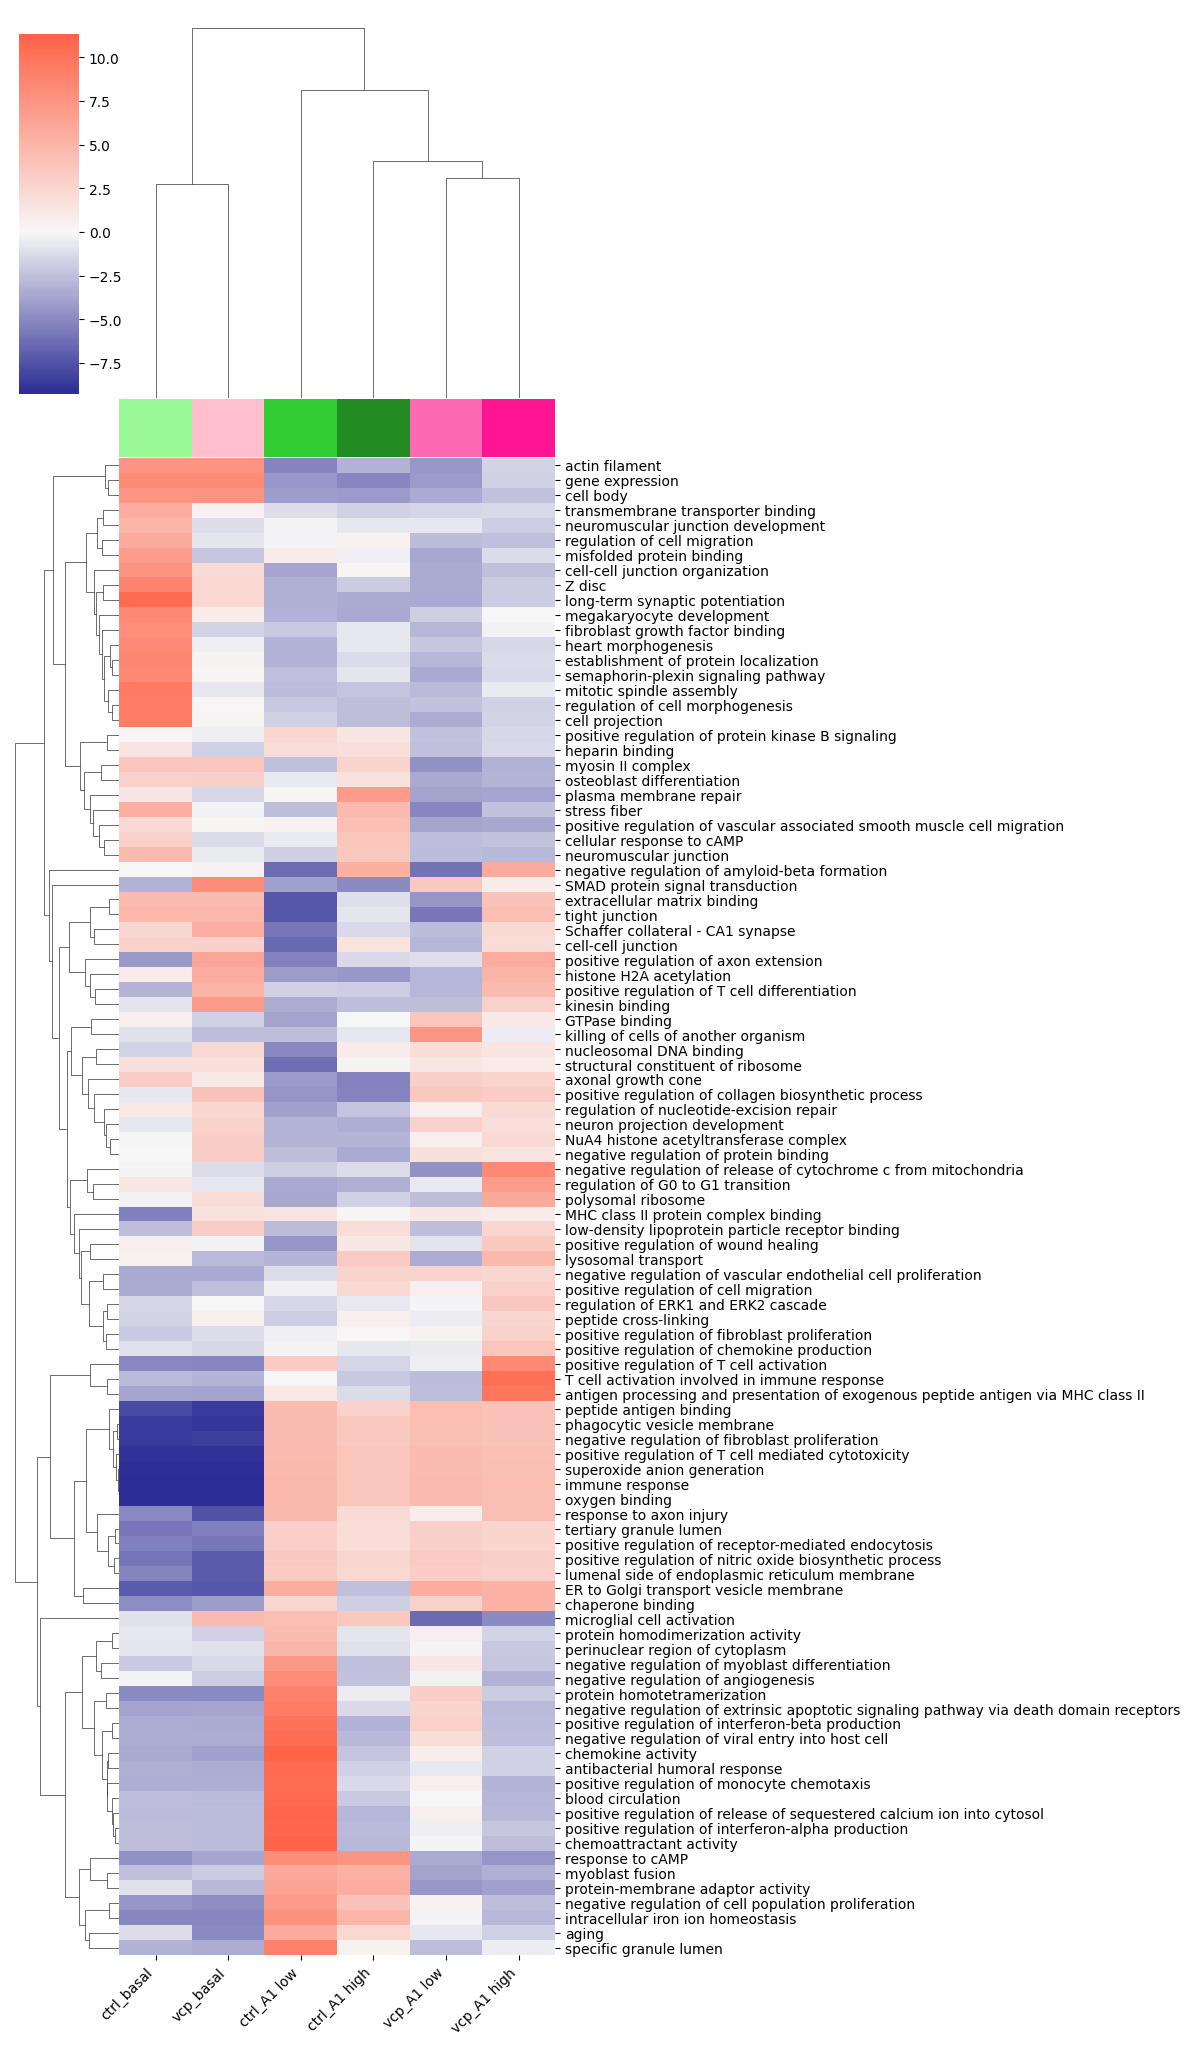

In [275]:
# First try with standard scaling
g = sns.clustermap(top_proj40, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=True, 
                    cmap=cmap,
                    center=0,
                    figsize=(12, 20))


g.ax_heatmap.set_xticklabels(
    g.ax_heatmap.get_xticklabels(), 
    rotation=45, 
    ha='right'
)